# Model Evaluation
---

### Imports

In [1]:
from pathlib import Path
from src.utils import get_device

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from src.model import MyModel

/Users/aram/Desktop/7. Semester/Machine Vision and CNN/Knee-Segmentation/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Paths and device

In [2]:
PROJECT_DIR = Path.cwd()
TEST_CSV = PROJECT_DIR / "data" / "csv" / "test.csv"
CHECKPOINT = PROJECT_DIR / "sessions" / "best_model.pth"
DEVICE = get_device()

### Load test data

In [3]:
if not TEST_CSV.is_file():
    raise FileNotFoundError(f"Test CSV not found: {TEST_CSV}")
if not CHECKPOINT.is_file():
    raise FileNotFoundError(f"Model checkpoint not found: {CHECKPOINT}")

test_df = pd.read_csv(TEST_CSV, keep_default_na=False)
if test_df.empty:
    raise ValueError(f"The test CSV contains no images: {TEST_CSV}")

print(f"{len(test_df)} test images | Device: {DEVICE}")

90 test images | Device: mps


### Load model and define prediction helper

In [4]:
model = MyModel().to(DEVICE)
model.load_state_dict(torch.load(CHECKPOINT, map_location=DEVICE))
model.eval()


def predict_mask(image, threshold=0.5):
    """Return the binary segmentation mask for a grayscale image."""
    x = torch.from_numpy(image.astype(np.float32) / 255.0)
    x = x[None, None].to(DEVICE)  # shape: (1, 1, H, W)

    with torch.inference_mode():
        probs = torch.sigmoid(model(x))[0, 0].cpu().numpy()
    return probs >= threshold


def display_prediction(index, threshold=0.5):
    """Show one test X-ray, its predicted mask and an overlay."""
    path = Path(test_df.iloc[index]["xrays"])
    image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    mask = predict_mask(image, threshold)

    plt.figure(figsize=(16, 8))

    plt.subplot(1, 3, 1)
    plt.imshow(image, cmap="gray")
    plt.title("X-ray")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(mask, cmap="gray")
    plt.title(f"Predicted mask (threshold {threshold:.2f})")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(image, cmap="gray")
    plt.imshow(mask, cmap="autumn", alpha=0.45)
    plt.title("Mask overlay")
    plt.axis("off")

    plt.suptitle(f"Test image {index}: {path.name}")
    plt.tight_layout()
    plt.show()

### Save all mask overlays

Save an overlay image for every test X-ray to `sessions/mask_overlays/`.

In [5]:
OVERLAY_DIR = PROJECT_DIR / "sessions" / "mask_overlays"
OVERLAY_DIR.mkdir(parents=True, exist_ok=True)

for path in test_df["xrays"]:
    image_path = Path(path)
    image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    mask = predict_mask(image)

    plt.imshow(image, cmap="gray")
    plt.imshow(mask, cmap="autumn", alpha=0.45)
    plt.axis("off")
    plt.savefig(OVERLAY_DIR / f"{image_path.stem}.png", bbox_inches="tight", pad_inches=0)
    plt.close()

print(f"Overlays saved to {OVERLAY_DIR}")

Overlays saved to /Users/aram/Desktop/7. Semester/Machine Vision and CNN/Knee-Segmentation/sessions/mask_overlays


### Inspect predictions

In [7]:
image_index = 0

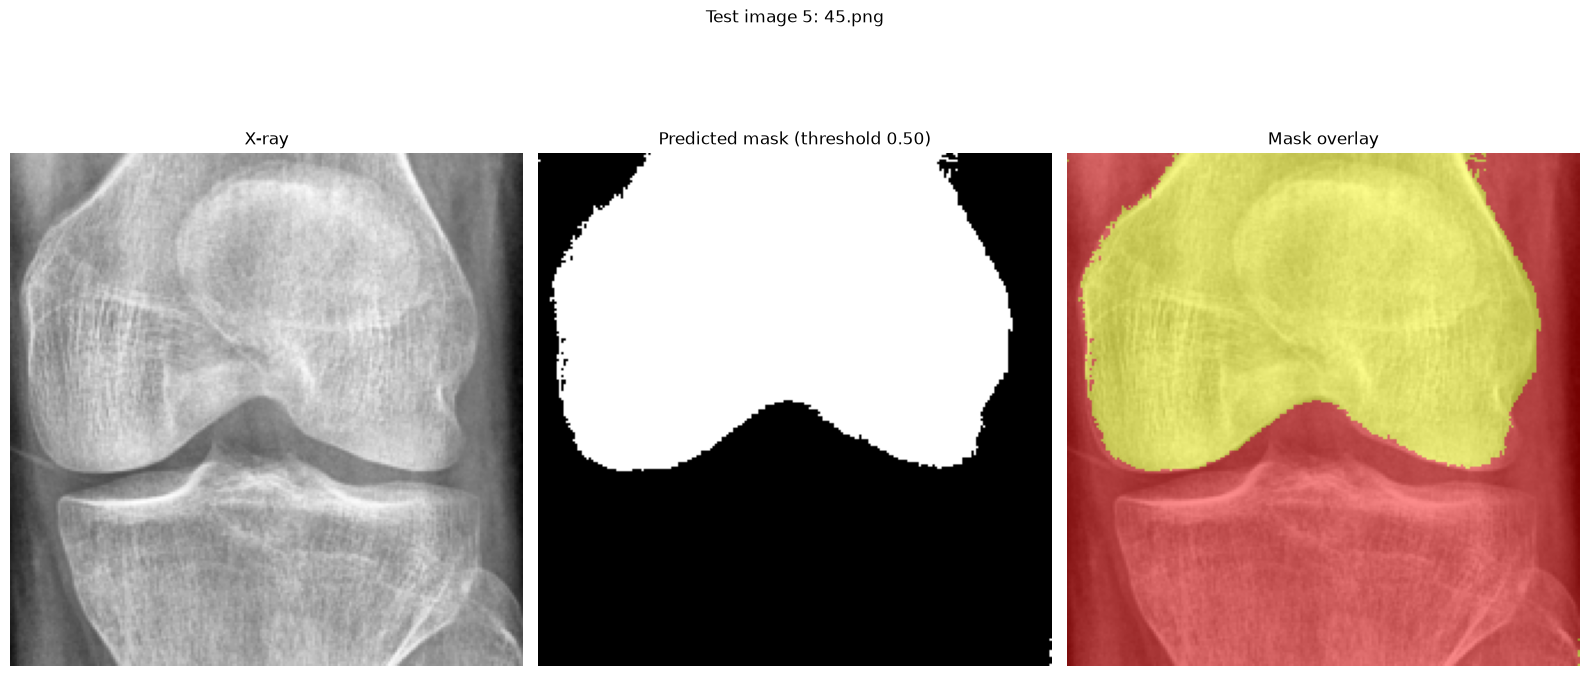

In [13]:
# Change the index and rerun this cell to inspect the next image.
display_prediction(image_index)
image_index += 1